<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_3_10_%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_26_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 5 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

100%|██████████| 734k/734k [00:00<00:00, 769kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/iammustafatz/diabetes-prediction-dataset/versions/1


In [27]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [4]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()


# gender  та smoking_history - object;  age, bmi, HbA1c_level - float;    hypertension,  heart_disease, heart_disease, diabetes - int


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [11]:
# TODO: підрахуйте частоти категорій у gender.
df.value_counts('gender')

,count
gender,
Female,58552
Male,41430
Other,18


In [12]:
# TODO: підрахуйте частоти категорій у smoking_history.
df.value_counts('smoking_history')

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [10]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [8]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


In [13]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [7]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

дизбаланс є і віе великий: 91 тисяча проти 8

Перевірити наявність пропущених даних


In [14]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [15]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [28]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [17]:
# TODO: df
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [18]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

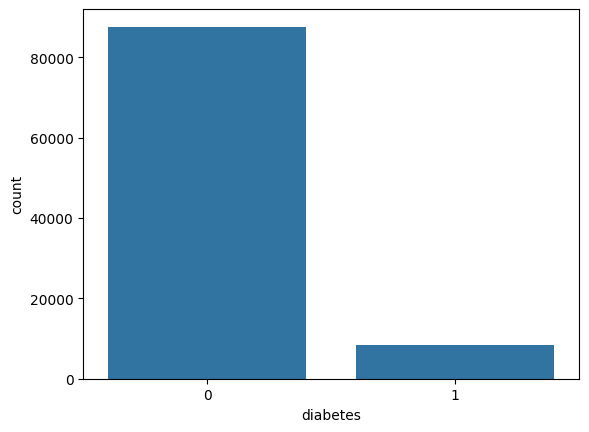

In [19]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [20]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [29]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
x = df.drop(columns="diabetes")
y = df["diabetes"]

x_train, x_test, y_train, y_test=train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [31]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

#x_train=pd.get_dummies(x_train, columns=['gender', 'smoking_history'], dtype=int)
#x_test=pd.get_dummies(x_test, columns=['gender', 'smoking_history'], dtype=int)
x_test=x_test.reindex(columns=x_train.columns, fill_value=0)

In [32]:
# TODO: виведіть статистики опису X_train.
x_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [33]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
x_train.corrwith(y_train).sort_values(ascending=False)

,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


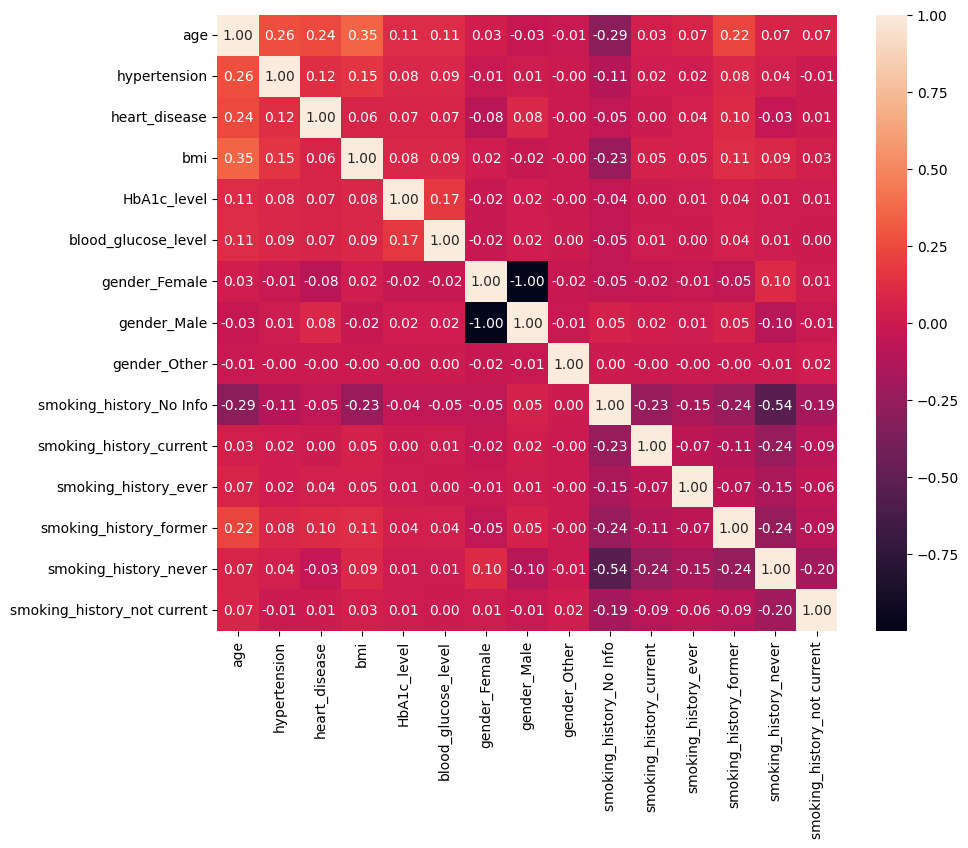

In [40]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).

plt.figure(figsize=(10, 8))
sns.heatmap(x_train.corr(), annot=True, fmt=".2f")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

як можемо побачити, з віком збільшуються такі показники, як hypertension, heart_disease, bmi, smoking_history_former. Чи потрібно видаляти ознаки? так, але лише технічні повтори типу genfer male, gender_femalе тощо

Перевірити викиди **лише на навчальній вибірці**

<function matplotlib.pyplot.show(close=None, block=None)>

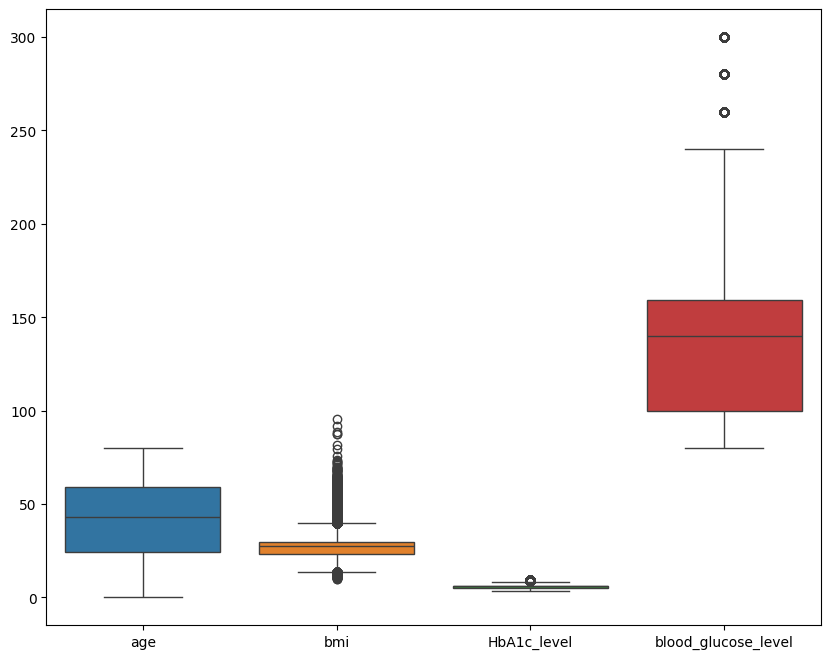

In [42]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continious_cols=['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(10, 8))
sns.boxplot(data=x_train[continious_cols])
plt.show

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [46]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
x_train[continious_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [50]:
# TODO: перевірте пропуски окремо в X_train та X_test.
x_train.isnull().sum()

,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


In [52]:
x_test.isnull().sum()

,0
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [53]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.fit_transform(x_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [54]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
x_train_balanced, y_train_balanced=SMOTE(random_state=42).fit_resample(x_train_scaled, y_train)
print(y_train.value_counts())
print(y_train_balanced.value_counts())

diabetes
0    70130
1     6786
Name: count, dtype: int64
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [55]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models={
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'RidgeClassifier': RidgeClassifier(),
    "SGDCClassifier": SGDClassifier(random_state=42),
    'SVC': SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


===== LogisticRegression =====
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.87      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



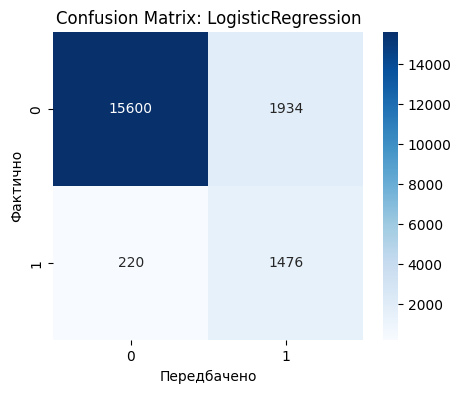

===== RidgeClassifier =====
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.44      0.87      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.91     19230



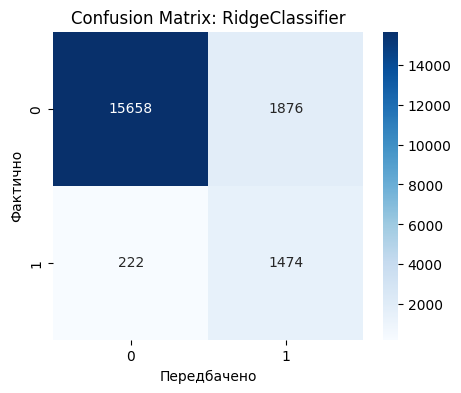

===== SGDCClassifier =====
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.39      0.91      0.54      1696

    accuracy                           0.87     19230
   macro avg       0.69      0.88      0.73     19230
weighted avg       0.94      0.87      0.89     19230



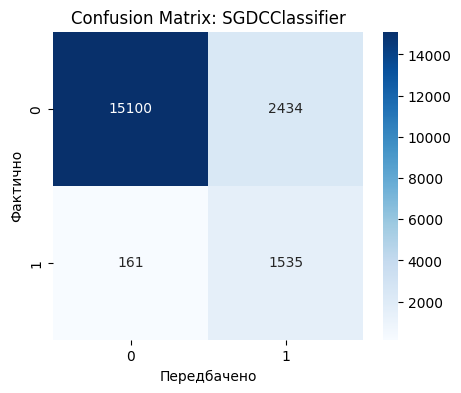

===== SVC =====
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.90      0.76     19230
weighted avg       0.94      0.89      0.90     19230



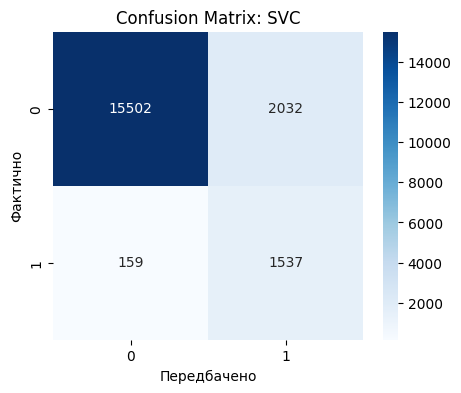

In [64]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).


for name, model in models.items():
    # 1. навчання на збалансованій вибірці
    model.fit(x_train_balanced, y_train_balanced)

    # 2. прогноз на масштабованій тестовій вибірці
    predictions = model.predict(x_test_scaled)

    # 3. звіт і матриця помилок
    print(f"===== {name} =====")
    print(classification_report(y_test, predictions))

    cm = confusion_matrix(y_test, predictions)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Передбачено")
    plt.ylabel("Фактично")
    plt.show()

Оптимізувати гіперпараметри


In [78]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param= {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1.0, 10.0]
    },
    'SGDCClassifier': {
        'loss': ["log_loss", 'hinge'],
        'alpha': [0.0001, 0.001, 0.01],
        'penalty': ['l2', 'l1']
    },
    "SVC": {
        "C":[0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [83]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [81]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\nПідбір параметрів")

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])
    params = {'model__' + key: values for key, values in param[name].items()}
    search = HalvingGridSearchCV(
        pipeline, params, scoring='f1', cv=3, factor=2,
        min_resources=300, random_state=42, n_jobs=1
    )
    search.fit(x_train, y_train)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print('Найкращі параметри:', search.best_params_)
    print('F1 на кросвалідації:', search.best_score_)
    predictions = search.best_estimator_.predict(x_test)
    print('Класифікаційний звіт на test:')
    print(classification_report(y_test, predictions, zero_division=0))


Підбір параметрів
Найкращі параметри: {'model__C': 0.01, 'model__solver': 'lbfgs'}
F1 на кросвалідації: 0.6530066677483408
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів
Найкращі параметри: {'model__alpha': 10.0}
F1 на кросвалідації: 0.5709793351302785
Класифікаційний звіт на test:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


Підбір параметрів
Найкращі параметри: {'model__alpha': 0.01

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [82]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
best_name=max(best_scores, key=best_scores.get)
best_model=best_models[best_name]
print('Найкраща', best_name, 'f1:', best_scores[best_name])

Найкраща LogisticRegression f1: 0.6530066677483408


In [89]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
random_indices=np.random.default_rng(42).choice(len(x_test), size=10, replace=False)
y_pred_best=best_model.predict(x_test.iloc[random_indices])

randomResults_df=pd.DataFrame({
    'Index': x_test.iloc[random_indices].index,
    'Справжні значення': y_test.iloc[random_indices].values,
    "Передбачано": y_pred_best
})
randomResults_df

,Index,Справжні значення,Передбачано
0,72555,0,1
1,42651,1,1
2,9181,0,0
3,67901,0,0
4,25253,0,0
5,58082,0,0
6,41116,0,1
7,63015,0,0
8,76480,0,0
9,15158,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

Ми маємо великий дизбаланс близький відношення 10 до 1. Кореляційний аналіз показав слабкі зв'язки між числовими ознаками і лише технічну кореляцію між  колонками